# Read UK rain radar data from cloud-hosted NetCDF4 files 

**Launch this notebook:**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NERC-CEH/access-FDRI-catchment-rain-radar/blob/main/from_cloud/read_radar_data_from_open_data_registry.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/NERC-CEH/access-FDRI-catchment-rain-radar/HEAD)

---
If you have issues accessing cloud data from JASMIN, see [CEDA status](https://www.ceda.ac.uk/status/)

**Setup**
Let's load the python libraries we need to read this data.  

In [1]:
# Python standard libaries
import datetime

# 3rd party libraries
import geopandas as gpd
import s3fs
import xarray as xr

import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Introduction
In this example, we will use the s3fs to access 5 min composite radar data from the [JASMIN Object Store](https://help.jasmin.ac.uk/docs/short-term-project-storage/object-store/jasmin-object-store/). The data had been subset to a 20km buffer around three river catchments:
* [River Chess at Ricksmanworth](https://nrfa.ceh.ac.uk/data/station/spatial/39088)
* [River Severn at Dolwen](https://nrfa.ceh.ac.uk/data/station/spatial/54080)
* [River Tweed at Peebles](https://nrfa.ceh.ac.uk/data/station/spatial/21003)

The data uploaded to JASMIN Object Store covers the period from Apr-2004 to Oct-2026 at time of writing (5 Nov 2026). The data may also have gaps, owing to underlying issues with the NIMROD composite.  

> You can think of loading data from JASMIN Object Store as "loading data from the cloud".

## Gallery (visualisations from this notebook)
<p float="left">
    <img src="https://raw.githubusercontent.com/NERC-CEH/access-FDRI-catchment-rain-radar/refs/heads/main/figures/dolwen_rainradar_2007_07_20_0900.png" alt="Dowlen-20Jul" style="width:250px;"/>
</p>

<p float="left">
    <img src="https://raw.githubusercontent.com/NERC-CEH/access-FDRI-catchment-rain-radar/refs/heads/main/figures/dolwen_rainradar_jul07_timeseries.png" alt="Dowlen-Jul" style="width:250px;"/>
</p>


<p float="left">
    <img src="https://raw.githubusercontent.com/NERC-CEH/access-FDRI-catchment-rain-radar/refs/heads/main/figures/peebles_catchment_extract.png" alt="Dowlen-Jul" style="width:250px;"/>
</p>

### Table of contents
1. Set up file reader for JASMIN Object Store 
2. Lazy-load NetCDF data
3. Subset and plot some data
4. Subset to exact NRFA river catchment bounds (optional)

# 1. Set up reader for JASMIN Object Store
Let's use `s3fs` to connect to, and open data from the JASMIN Object Store. The s3 bucket that we are interested in is called "rain-radar".  


**Table 1.** Path to objects in `rain-radar` s3 bucket:
| catchment | s3 path to data | coverage |endpoint |
| --- | ------- | --- | --- |
| Chess | s3://rain-radar/NIMROD-subsets/Chess-20km-buffer | Apr-2014 to Oct-2026 | https://fdri-o.s3-ext.jc.rl.ac.uk |
| Severn | s3://rain-radar/NIMROD-subsets/Dolwen-20km-buffer | Apr-2014 to Oct-2026 | https://fdri-o.s3-ext.jc.rl.ac.uk |
| Tweed | s3://rain-radar/NIMROD-subsets/Peebles-20km-buffer | Apr-2014 to Oct-2026 | https://fdri-o.s3-ext.jc.rl.ac.uk |


*Note: data in the "rain-radar" bucket is available free and anonymously (as of Nov 2026), but this access policy may change.*

Let's load rain radar data around the River Chess...

In [2]:
# Define which s3 bucket the data is in, and the catchment folder we are interested in
bucket_name = "rain-radar"
chess_catchment_folder = "NIMROD-subsets/Chess-20km-buffer"

Set up the s3fs filesystem object and connect anonymously

In [3]:
fs = s3fs.S3FileSystem(
    client_kwargs={"endpoint_url": "https://fdri-o.s3-ext.jc.rl.ac.uk"},
    anon=True
)

Let's take a look at filepaths for the year 2025...

In [4]:
# search files for data we want for our chosen data
chess_2025_paths = fs.glob(f"{bucket_name}/{chess_catchment_folder}/2025*.nc") 

In [5]:
len(chess_2025_paths)

12

In [6]:
chess_2025_paths[:5]

['rain-radar/NIMROD-subsets/Chess-20km-buffer/202501.nc',
 'rain-radar/NIMROD-subsets/Chess-20km-buffer/202502.nc',
 'rain-radar/NIMROD-subsets/Chess-20km-buffer/202503.nc',
 'rain-radar/NIMROD-subsets/Chess-20km-buffer/202504.nc',
 'rain-radar/NIMROD-subsets/Chess-20km-buffer/202505.nc']

In [7]:
# we can open those files as objects with...
chess_2025_files = [fs.open(p) for p in chess_2025_paths]

In [8]:
chess_2025_files[:5]

[<File-like object S3FileSystem, rain-radar/NIMROD-subsets/Chess-20km-buffer/202501.nc>,
 <File-like object S3FileSystem, rain-radar/NIMROD-subsets/Chess-20km-buffer/202502.nc>,
 <File-like object S3FileSystem, rain-radar/NIMROD-subsets/Chess-20km-buffer/202503.nc>,
 <File-like object S3FileSystem, rain-radar/NIMROD-subsets/Chess-20km-buffer/202504.nc>,
 <File-like object S3FileSystem, rain-radar/NIMROD-subsets/Chess-20km-buffer/202505.nc>]

# 2. Lazy-load NetCDF data
Now that we have a connection to the data within the s3 bucket, let's load the data in locally.   
The data files can be [lazy-loaded](https://en.wikipedia.org/wiki/Lazy_loading) with xarray. Meaning that the data will not be loaded into memory when read, and because this data is "chunked" into 14 day periods, this will let us seemlessly extract time subsets of it without requiring too much RAM. 

*For an excellent introduction to chunking, and how accessing data from Object Store please see the [Object Store Tutorial](https://github.com/NERC-CEH/object_store_tutorial#dataset-chunking).*

In [9]:
chess_2025 = xr.open_mfdataset(chess_2025_files)

Because the data is only 1.3 GiB for one year of Chess at Rickmansworth, we could load it all into memory, you can do that with `.load()`

In [10]:
## Comment out below if you are not memory-limited to load the entire year worth of data
# chess_2025.load()

# 3. Subset and plot some data
Next, we'll show you how to load in and plot some data.  
For the purpose showing lazy-loading and subsetting, we'll load in the entire time-period of Dolwen catchment...

In [11]:
dolwen_catchment_folder =  "NIMROD-subsets/Dolwen-20km-buffer"

In [12]:
# we can open those files as objects with...
dolwen_paths = fs.glob(f"{bucket_name}/{dolwen_catchment_folder}/*.nc") 
print(len(dolwen_paths))
dolwen_files = [fs.open(p) for p in dolwen_paths]

270


Lazy-load all data for Dolwen

In [ ]:
## This is for all 270 files (so can take around 5 mins to prepare)
dolwen_rain_radar = xr.open_mfdataset(dolwen_files)

In [14]:
# You may see that the total disk size of the rainfall_mm variable is around 32 GiB, with a chunk size of 58 MiB
dolwen_rain_radar

<xarray.Dataset> Size: 35GB
Dimensions:      (time: 2282078, y: 61, x: 62)
Coordinates:
  * time         (time) datetime64[ns] 18MB 2004-04-06T22:50:00 ... 2026-10-2...
  * y            (y) float64 488B 3.155e+05 3.145e+05 ... 2.565e+05 2.555e+05
  * x            (x) float64 496B 2.615e+05 2.625e+05 ... 3.215e+05 3.225e+05
Data variables:
    rainfall_mm  (time, y, x) float32 35GB dask.array<chunksize=(4032, 61, 62), meta=np.ndarray>

### Upper Severn July 2007 case study
For the Upper Severn, July 2007 was associate with serious flooding, so we will take data from that month

In [15]:
dolwen_jul07 = dolwen_rain_radar.sel(time="2007-07")

In [16]:
dolwen_jul07 # disk size should be 121.52 MiB

<xarray.Dataset> Size: 127MB
Dimensions:      (time: 8423, y: 61, x: 62)
Coordinates:
  * time         (time) datetime64[ns] 67kB 2007-07-01 ... 2007-07-31T23:55:00
  * y            (y) float64 488B 3.155e+05 3.145e+05 ... 2.565e+05 2.555e+05
  * x            (x) float64 496B 2.615e+05 2.625e+05 ... 3.215e+05 3.225e+05
Data variables:
    rainfall_mm  (time, y, x) float32 127MB dask.array<chunksize=(4032, 61, 62), meta=np.ndarray>

In [17]:
dolwen_jul07.load()

<xarray.Dataset> Size: 127MB
Dimensions:      (time: 8423, y: 61, x: 62)
Coordinates:
  * time         (time) datetime64[ns] 67kB 2007-07-01 ... 2007-07-31T23:55:00
  * y            (y) float64 488B 3.155e+05 3.145e+05 ... 2.565e+05 2.555e+05
  * x            (x) float64 496B 2.615e+05 2.625e+05 ... 3.215e+05 3.225e+05
Data variables:
    rainfall_mm  (time, y, x) float32 127MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0

On 20th July 2007, 90mm fell over Gloucester, so let's have a look at one 5min time-step at 9 am

In [18]:
date_time_to_examine = datetime.datetime(2007, 7, 20, 9, 0)


Let's also load the Severn catchment boundary at Dolwen

In [19]:
dolwen_shp = gpd.read_file("../spatial_data/Dolwen/54080/54080.shp")

Below we plot the radar rainfall rate at that given 5min timestep, the catchment outline and the 20km buffer of the catchment

Text(0.375, 0.24, 'Data: 1 km composite rain radar (NIMROD)')

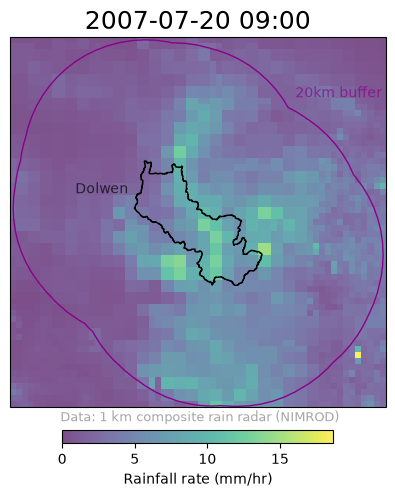

In [20]:
fig, ax = plt.subplots(1, subplot_kw={'projection': ccrs.OSGB()}, figsize=(10, 6))

# Plot radar rain rate
dolwen_jul07['rainfall_mm'].sel(time=date_time_to_examine).plot(
    vmin=0, ax=ax, alpha=.7,
    add_colorbar=True, cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.35, 'pad': 0.05, 'label': 'Rainfall rate (mm/hr)'},
    transform=ccrs.OSGB())

# Plot catchment outlines
dolwen_shp.plot(ax=ax, facecolor='none')
buffer_size = 20000 # 20 km (change if appropriate)
dolwen_shp.buffer(buffer_size).plot(ax=ax, facecolor='none', edgecolor="darkmagenta") # 20km

# add titles and text
ax.set_title(date_time_to_examine.strftime("%Y-%m-%d %H:%M"), size=18);
fig.text(s="Dolwen", x=.39, y=.62, c="k", alpha=.7)
fig.text(s="20km buffer", x=.61, y=.78, c="darkmagenta", alpha=.7)
fig.text(s="Data: 1 km composite rain radar (NIMROD)",size=9, x=.375, y=.24, c='grey', alpha=.7)
# fig.savefig(f"../figures/dolwen_rainradar_{date_time_to_examine.strftime("%Y_%m_%d_%H%M")}.png", bbox_inches='tight', dpi=150)

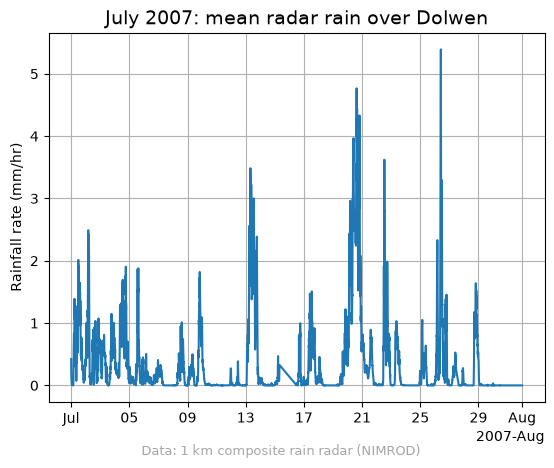

In [21]:
fig, ax = plt.subplots(1)
dolwen_jul07['rainfall_mm'].mean(('y', 'x')).plot(ax=ax)
ax.set_title("July 2007: mean radar rain over Dolwen", size=14)
fig.text(s="Data: 1 km composite rain radar (NIMROD)",size=9, x=.27, y=.0, c='grey', alpha=.7)
ax.set_ylabel("Rainfall rate (mm/hr)"); ax.set_xlabel("");
ax.grid()
# fig.savefig(f"../figures/dolwen_rainradar_jul07_timeseries.png", bbox_inches='tight', dpi=150)

# 4. Subset to exact NRFA river catchment bounds (optional)
Because the data is in xarray format, we can mask out regions of it. Let's mask out the exact river catchment using the catchment boundary from NRFA.

Other examples of masking a catchment like this are shown in FDRI's [access-UK-radar notebooks](https://github.com/NERC-CEH/access-UK-radar-data).

In [22]:
## Comment out below if you would like to run this section
# %%capture
# !pip install rioxarray rasterio

In [23]:
import numpy as np
import rioxarray

## Load in UK 1km mask GeoTIFF
We are working with Shapefiles of catchment boundaries, which cannot be directly loaded into xarray, so we'll use a GeoTIFF file and the library [rasterio](https://corteva.github.io/rioxarray/stable/index.html) to leverage [rasterio](https://rasterio.readthedocs.io/en/latest/index.html) to create a 1km by 1km mask that can subset xarray.

In [24]:
uk_hght = rioxarray.open_rasterio("../spatial_data/uk_cehgear_mask.tif")

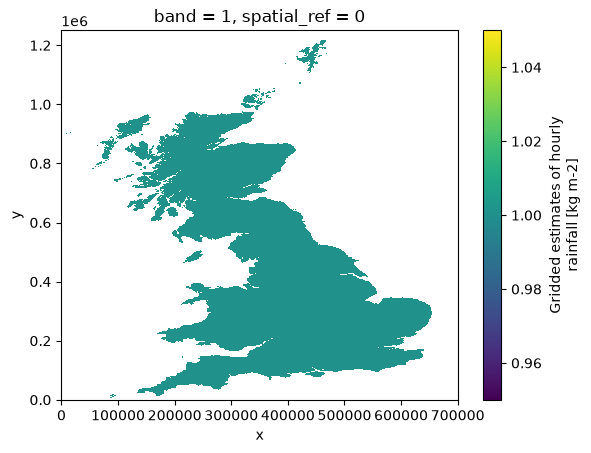

In [25]:
uk_hght.plot()

Annoyingly, the x and y dimensions are 500 m off between NIMROD-subset and this GeoTIFF, so let's quickly fix that...

In [26]:
def shift_data_by_offset(data, shift_in_m=500):
    dx = shift_in_m
    dy = shift_in_m

    new_x = np.round(data['x']) + dx
    new_y = np.round(data['y']) + dy

    shifted_data = data.interp(x=new_x, y=new_y)
    shifted_data = shifted_data.assign_coords(x=new_x)
    shifted_data = shifted_data.assign_coords(y=new_y)
    shifted_data = shifted_data.fillna(-1.)
    return shifted_data

In [27]:
uk_hght_shifted = shift_data_by_offset(uk_hght)

## Load in Peebles rain radar data for 1 year

In [28]:
peebles_catchment_folder =  "NIMROD-subsets/Peebles-20km-buffer"
year_subset = "2019" # in the interest of speeding this up, we'll subset it by filename to a single year

In [29]:
peebles_paths = fs.glob(f"{bucket_name}/{peebles_catchment_folder}/{year_subset}*.nc") 
print(len(peebles_paths))
peebles_files = [fs.open(p) for p in peebles_paths]

12


In [30]:
## This is for all 270 files (so takes around 2-5 mins to prepare)
peebles_rain_radar = xr.open_mfdataset(peebles_files)

In [31]:
peebles_rain_radar

<xarray.Dataset> Size: 2GB
Dimensions:      (time: 103212, y: 87, x: 67)
Coordinates:
  * time         (time) datetime64[ns] 826kB 2019-01-01 ... 2019-12-31T23:55:00
  * y            (y) float64 696B 6.795e+05 6.785e+05 ... 5.945e+05 5.935e+05
  * x            (x) float64 536B 2.815e+05 2.825e+05 ... 3.465e+05 3.475e+05
Data variables:
    rainfall_mm  (time, y, x) float32 2GB dask.array<chunksize=(4032, 87, 67), meta=np.ndarray>

## Load NRFA boundary and create mask
In this case, we'll load the Peebles catchment

In [32]:
nrfa_shp = gpd.read_file("../spatial_data/Peebles/21003/21003.shp")

In [33]:
def make_region_hght_clip(region_shp, hght_data):
    """Clip region by height raster"""
    region_clip = hght_data.rio.clip(
        region_shp.geometry.values, region_shp.crs, drop=False, invert=False
    )
    return region_clip

In [34]:
buffer_size = 20000 # Subset of rain radar data is 20km
nrfa_shp_buffer = nrfa_shp.buffer(buffer_size)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

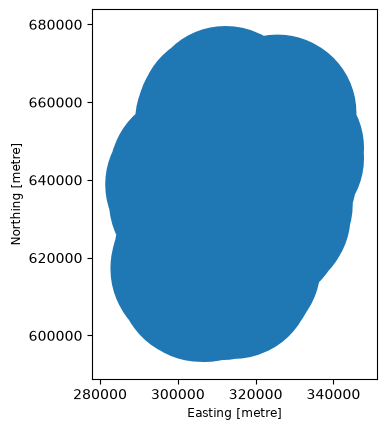

In [35]:
nrfa_shp_buffer.plot()

In [36]:
# Make catchment mask, and clip that catchment mask to the same bounds as the radar data
catchment_mask = make_region_hght_clip(nrfa_shp, uk_hght_shifted)

catchment_mask = catchment_mask.sel(
    x=slice(nrfa_shp_buffer.bounds['minx'][0], nrfa_shp_buffer.bounds['maxx'][0]),
    y=slice(nrfa_shp_buffer.bounds['maxy'][0], nrfa_shp_buffer.bounds['miny'][0]), 
)

Now we have a mask

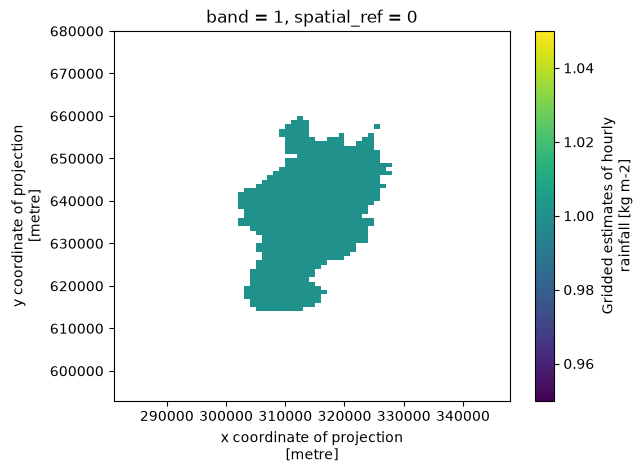

In [37]:
catchment_mask.plot()

In [40]:
def binarize_hght_clip(region_data):
    """
    Make binary mask of clipped region data data
    """
    return region_data / region_data.where(region_data > 0)
    
def mask_region_rainfall(rainfall_data, region_mask):
    """
    Mask region by binary height raster
    """
    return rainfall_data * binarize_hght_clip(region_mask).data

In [41]:
# Mask rainfall based on catchment mask
peebles_masked_rainfall = mask_region_rainfall(peebles_rain_radar, catchment_mask)

In [42]:
date_time_to_examine = "2019-03-12 00:00"

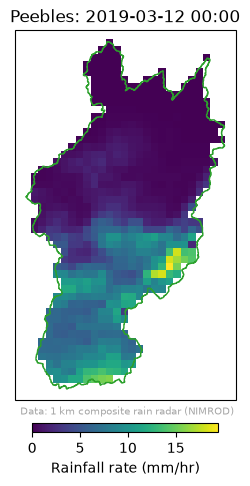

In [43]:
fig, ax = plt.subplots(1, subplot_kw={'projection': ccrs.OSGB()}, figsize=(12, 6))
peebles_masked_rainfall.sel(time=date_time_to_examine)['rainfall_mm'].plot(ax=ax, transform=ccrs.OSGB(),
    add_colorbar=True, cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.2, 'pad': 0.05, 'label': 'Rainfall rate (mm/hr)'})
nrfa_shp.plot(ax=ax, facecolor="none", edgecolor="C2", transform=ccrs.OSGB())

fig.text(s="Data: 1 km composite rain radar (NIMROD)",size=7, x=.425, y=.24, c='grey', alpha=.7)
ax.set_title(f"Peebles: {date_time_to_examine}")
ax.set_ylim(nrfa_shp.bounds['miny'][0]-1500, nrfa_shp.bounds['maxy'][0]+1500); ax.set_xlim(nrfa_shp.bounds['minx'][0]-1500, nrfa_shp.bounds['maxx'][0]+1500);
# fig.savefig(f"../figures/peebles_catchment_extract.png", bbox_inches='tight', dpi=150)